In [26]:
import pandas as pd
import xgboost as xgb
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [37]:
# 1. Load the data
data = pd.read_csv('merged.csv')
# Drop the specified columns
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber']
data.drop(columns=columns_to_drop, inplace=True)

# Rename columns to avoid characters that XGBoost doesn't like
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

print(data.head())

   jet_pt_:_0  ph_eta_:_0  ph_pt_:_0  ph_eta_:_1  ph_mlph_closest_:_1  \
0   164671.47    0.166258   48412.71    0.125178            34007.125   
1    62718.79    0.517340  109454.78    0.055620            65656.250   
2   300514.97   -1.060248  140199.05    1.363728           165863.640   
3   194324.39    0.817930   76016.17    1.195615            69155.805   
4   122342.50    0.127331  145933.60   -0.760747           116490.030   

          diph_M  event_njets    event_ST  event_nbjets77  dr_lep_ph0  \
0   61368.205887            4   530709.44               1    3.107354   
1  149053.577921            4   454574.97               2    2.659743   
2  339836.368995            4  1019295.30               2    2.831117   
3   97542.680173            5   767414.30               2    1.433745   
4   51048.634456            4   593776.80               2    1.877826   

   dr_lep_ph1  ph_conversion_type_:_1  ph_conversion_type_:_0  Label  \
0    0.952916                       1             

In [38]:
# Separate features (X) and labels (y)
X = data.drop(columns=['Weight','Label'])  # Replace 'target_column_name' with your actual target column name
w = data['Weight']
y = data['Label']  # Replace 'target_column_name' with your actual target column name

In [39]:
# Assuming the last column is the target variable and the rest are features.
#X = data.iloc[:, :-1]
#y = data.iloc[:, -1]

# 2. Preprocess the data
# For simplicity, fill missing values with the median and convert categorical columns using one-hot encoding.
# X = X.fillna(X.median())
# X = pd.get_dummies(X)


# 3. Split the data into training and testing sets
X_train, X_test, w_train, w_test, y_train, y_test = train_test_split(X, w, y, test_size=0.2, random_state=42)

In [45]:
# 4. Train an XGBoost model on the training set
model = xgb.XGBClassifier(tree_method='hist')
#model = GradientBoostingClassifier(verbose=1)
model.fit(X_train, y_train, sample_weight=np.abs(w_train))

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

In [46]:
# 5. Evaluate the model on the testing set
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred, sample_weight=w_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 66.34%


In [42]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc


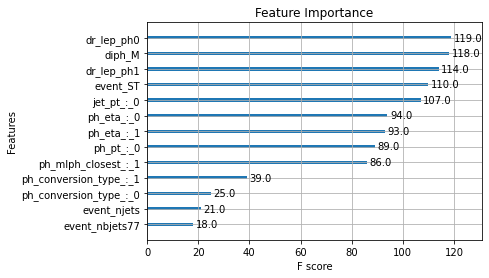

In [47]:
xgb.plot_importance(model)
plt.title('Feature Importance')
plt.show()

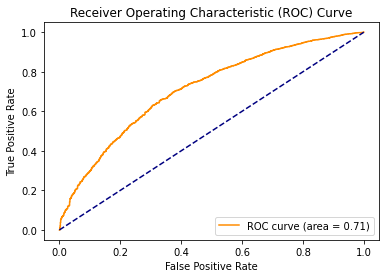

In [48]:
y_pred_prob = model.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()


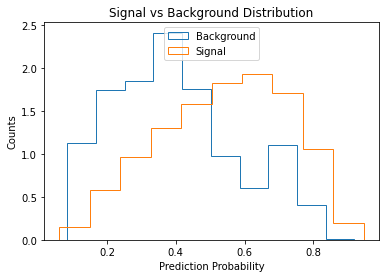

In [49]:
plt.hist(y_pred_prob[y_test == 0], weights=w_test[y_test ==0], bins=10, label='Background', histtype='step',density=True)
plt.hist(y_pred_prob[y_test == 1], weights=w_test[y_test ==1], bins=10, label='Signal', histtype='step',density=True)
plt.xlabel('Prediction Probability')
plt.ylabel('Counts')
plt.legend(loc="upper center")
plt.title('Signal vs Background Distribution')
plt.show()

In [50]:
event_counts = data['Label'].value_counts()
background_count = event_counts[0]
signal_count = event_counts[1]

print(f"Number of signal events: {signal_count}")
print(f"Number of background events: {background_count}")


Number of signal events: 341981
Number of background events: 4562


<Figure size 36000x14400 with 0 Axes>

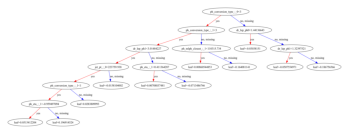

In [66]:
# Set the size of the plot
import matplotlib.pyplot as plt
plt.figure(figsize=(500,200))  # You can adjust the figure size to suit your needs

xgb.plot_tree(model, num_trees=0)   #uses xgboost's graphviz. num_trees 0 to show first tree
plt.savefig('xgboost_tree_0.png')  # Save the plot as a PNG file
plt.show()


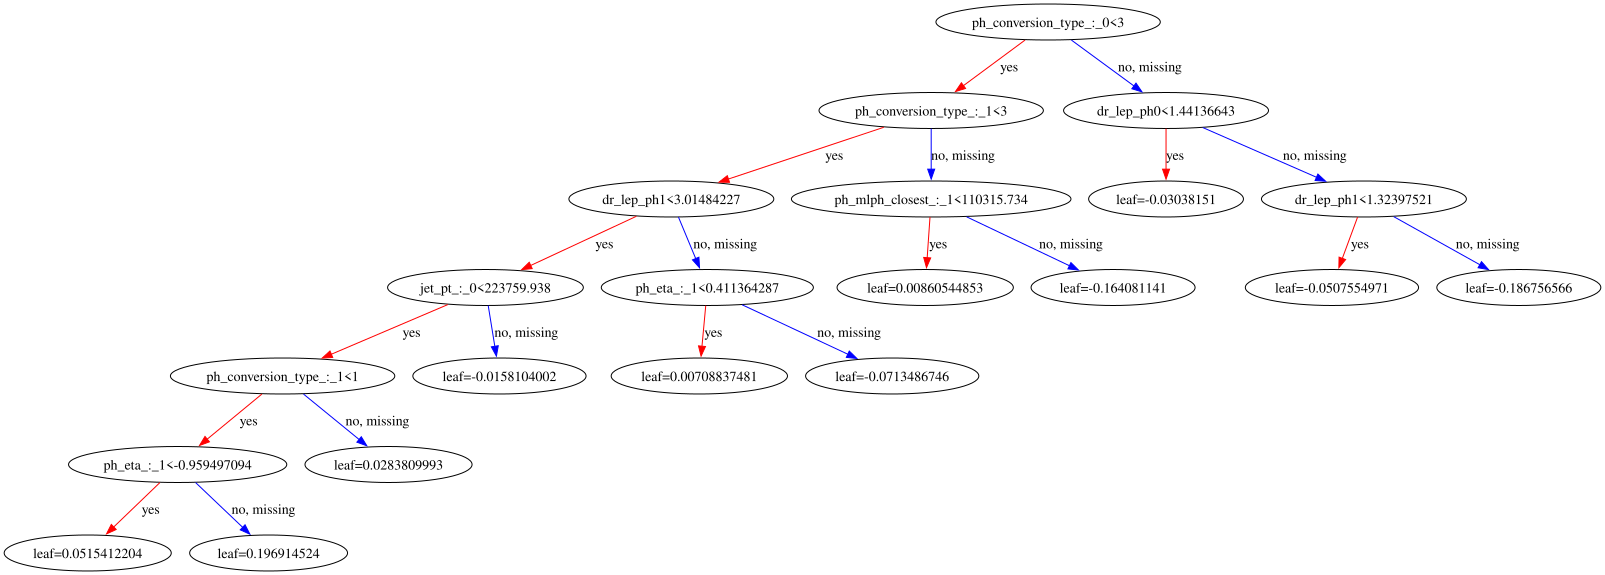

In [68]:

# Save the tree as a dot file
xgb.to_graphviz(model, num_trees=0, format='dot', outfile='xgboost_tree_0.dot')

# You can convert this dot file to a PNG file using graphviz command line tools
# Run the following command in your terminal (not in Jupyter):
# dot -Tpng xgboost_tree_0.dot -o xgboost_tree_0.png


In [70]:
# To save the DOT file. For converting to PNG:
# $ dot -Tpng xgboost_tree_0.dot -o xgboost_tree_0.png 
import os

# Assuming your model is named 'model' and is already trained
# Generate the graphviz instance (DAG) for the first tree
graph = xgb.to_graphviz(model, num_trees=0)

# Define the file path for the DOT file
dot_file_path = os.path.join(os.getcwd(), 'xgboost_tree_0.dot')

# Write the DOT data to a file
with open(dot_file_path, 'w') as dot_file:
    dot_file.write(graph.source)

print(f"DOT file saved at: {dot_file_path}")


DOT file saved at: /Users/arpanghosal/Work/Software_tutorials/gitprojects/xgboost/xgboost_tree_0.dot


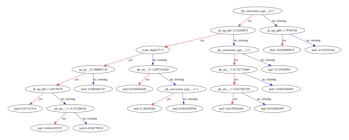

In [59]:
xgb.plot_tree(model, num_trees=1)    # For example, to visualize the second tree
plt.show()

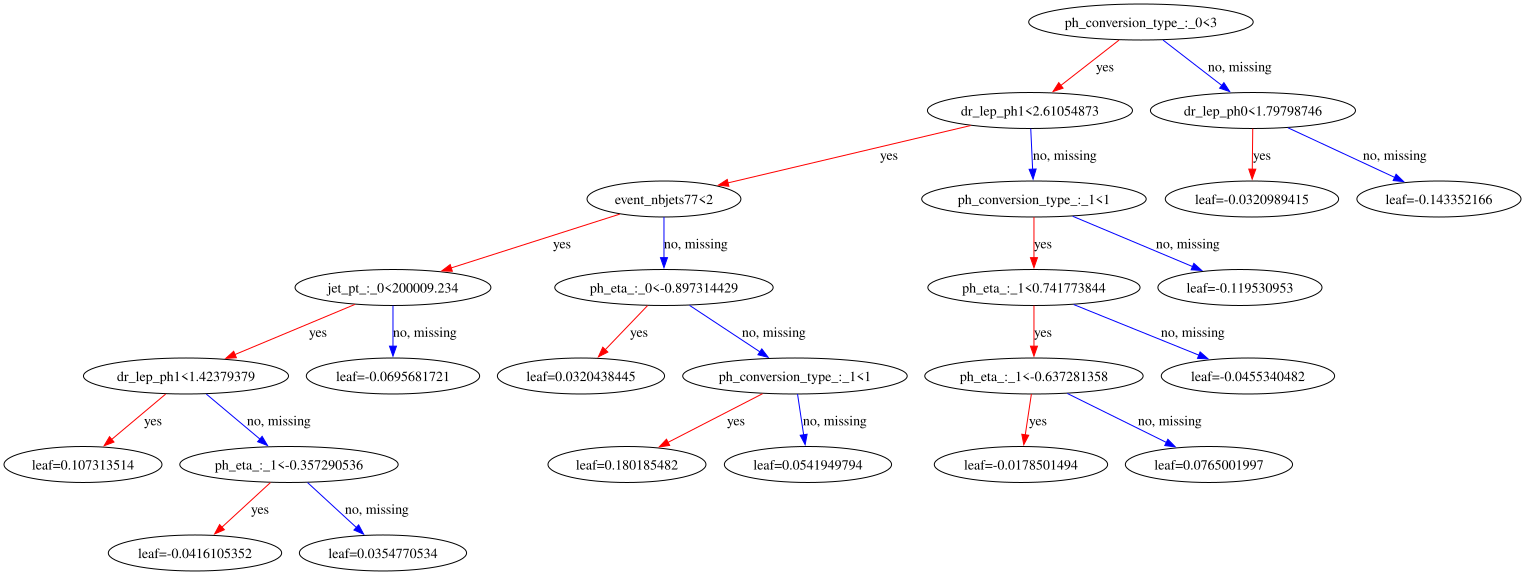

In [71]:
xgb.to_graphviz(model, num_trees=1, format='dot', outfile='xgboost_tree_1.dot')

In [25]:
import pandas as pd
from sklearn.utils import resample

# 1. Load the data
data = pd.read_csv('merged.csv')

# Separate signal and background
signal = data[data['Label'] == 1]
background = data[data['Label'] == 0]

# Upsampling background
background_upsampled = resample(background,
                                replace=True,                 # sample with replacement
                                n_samples=len(signal),       # to match majority class
                                random_state=42)             # reproducible results

# Combine majority class with upsampled minority class
upsampled = pd.concat([signal, background_upsampled])

# Downsampling signal
signal_downsampled = resample(signal,
                              replace=False,                # sample without replacement
                              n_samples=len(background),    # to match minority class
                              random_state=42)              # reproducible results

# Combine minority class with downsampled majority class
downsampled = pd.concat([signal_downsampled, background])

# Display new class counts
print("Upsampled dataset class distribution:\n", upsampled['Label'].value_counts())
print("\nDownsampled dataset class distribution:\n", downsampled['Label'].value_counts())


Upsampled dataset class distribution:
 Label
1    341981
0    341981
Name: count, dtype: int64

Downsampled dataset class distribution:
 Label
1    3180
0    3180
Name: count, dtype: int64


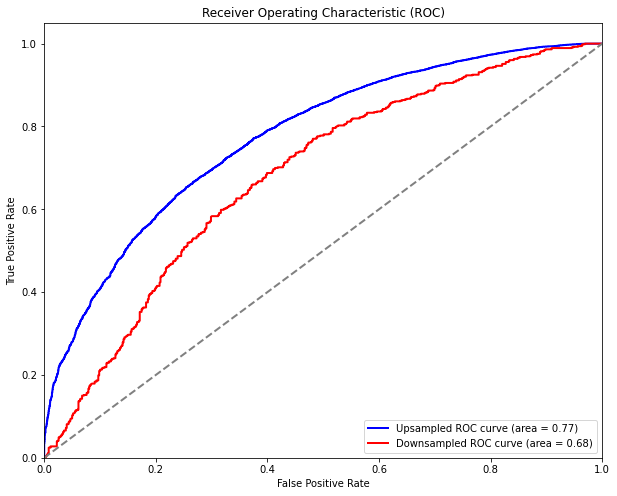

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import xgboost as xgb

# Load the data
data = pd.read_csv('merged.csv')

# Drop the specified columns
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns to avoid characters that XGBoost doesn't like
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

# Separate signal and background
signal = data[data['Label'] == 1]
background = data[data['Label'] == 0]

# Upsampling background
background_upsampled = resample(background, replace=True, n_samples=len(signal), random_state=42)
upsampled = pd.concat([signal, background_upsampled])

# Downsampling signal
signal_downsampled = resample(signal, replace=False, n_samples=len(background), random_state=42)
downsampled = pd.concat([signal_downsampled, background])

# Separate features and labels
def get_features_labels(df):
    X = df.drop('Label', axis=1)
    y = df['Label']
    return X, y

X_up, y_up = get_features_labels(upsampled)
X_down, y_down = get_features_labels(downsampled)

# Splitting the datasets
X_train_up, X_test_up, y_train_up, y_test_up = train_test_split(X_up, y_up, test_size=0.2, random_state=42)
X_train_down, X_test_down, y_train_down, y_test_down = train_test_split(X_down, y_down, test_size=0.2, random_state=42)

# XGBoost model
model = xgb.XGBClassifier(objective='binary:logistic', learning_rate=0.1, max_depth=5, n_estimators=100)

def train_evaluate(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    return fpr, tpr, roc_auc

# Upsampled dataset
fpr_up, tpr_up, roc_auc_up = train_evaluate(model, X_train_up, y_train_up, X_test_up, y_test_up)

# Downsampled dataset
fpr_down, tpr_down, roc_auc_down = train_evaluate(model, X_train_down, y_train_down, X_test_down, y_test_down)

# Plotting ROC Curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_up, tpr_up, color='blue', lw=2, label=f'Upsampled ROC curve (area = {roc_auc_up:.2f})')
plt.plot(fpr_down, tpr_down, color='red', lw=2, label=f'Downsampled ROC curve (area = {roc_auc_down:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()



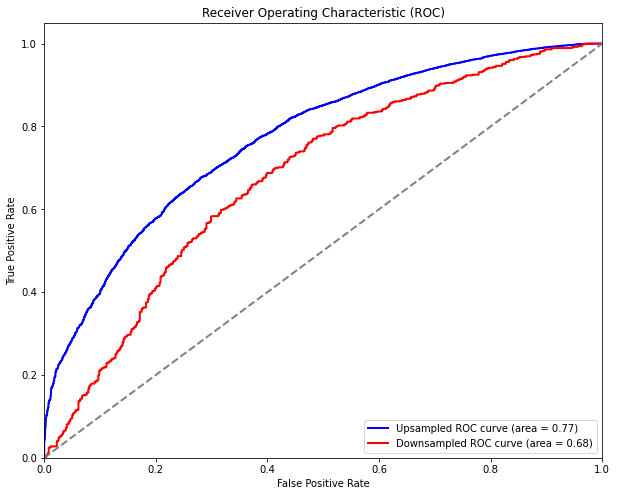

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import xgboost as xgb

# Load the data
data = pd.read_csv('merged.csv')

# Drop the specified columns
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns to avoid characters that XGBoost doesn't like
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

# Separate signal and background
signal = data[data['Label'] == 1]
background = data[data['Label'] == 0]

# Upsampling background
background_upsampled = resample(background, replace=True, n_samples=len(signal), random_state=42)
upsampled = pd.concat([signal, background_upsampled])

# Downsampling signal
signal_downsampled = resample(signal, replace=False, n_samples=len(background), random_state=42)
downsampled = pd.concat([signal_downsampled, background])

# Separate features and labels
def get_features_labels(df):
    X = df.drop('Label', axis=1)
    y = df['Label']
    return X, y

X_up, y_up = get_features_labels(upsampled)
X_down, y_down = get_features_labels(downsampled)

# Splitting the datasets
X_train_up, X_test_up, y_train_up, y_test_up = train_test_split(X_up, y_up, test_size=0.2)
X_train_down, X_test_down, y_train_down, y_test_down = train_test_split(X_down, y_down, test_size=0.2, random_state=42)

# XGBoost model
model = xgb.XGBClassifier(objective='binary:logistic', learning_rate=0.1, max_depth=5, n_estimators=100)

def train_evaluate(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    return fpr, tpr, roc_auc

# Upsampled dataset
fpr_up, tpr_up, roc_auc_up = train_evaluate(model, X_train_up, y_train_up, X_test_up, y_test_up)

# Downsampled dataset
fpr_down, tpr_down, roc_auc_down = train_evaluate(model, X_train_down, y_train_down, X_test_down, y_test_down)

# Plotting ROC Curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_up, tpr_up, color='blue', lw=2, label=f'Upsampled ROC curve (area = {roc_auc_up:.2f})')
plt.plot(fpr_down, tpr_down, color='red', lw=2, label=f'Downsampled ROC curve (area = {roc_auc_down:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()



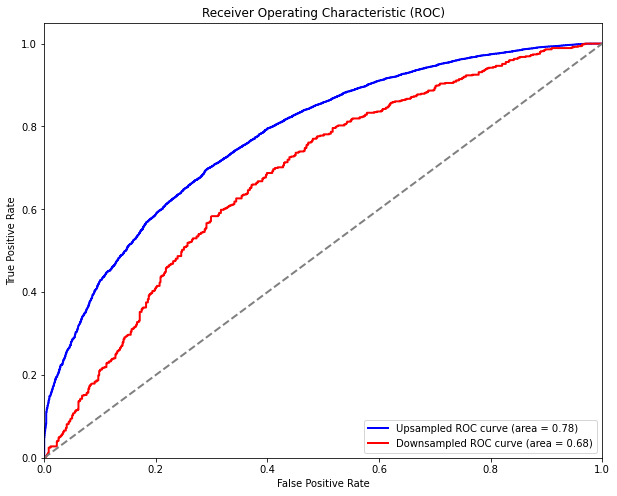

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import xgboost as xgb

# Load the data
data = pd.read_csv('merged.csv')

# Drop the specified columns
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns to avoid characters that XGBoost doesn't like
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

# Separate signal and background
signal = data[data['Label'] == 1]
background = data[data['Label'] == 0]

# Upsampling background
background_upsampled = resample(background, replace=True, n_samples=len(signal), random_state=42)
upsampled = pd.concat([signal, background_upsampled])

# Downsampling signal
signal_downsampled = resample(signal, replace=False, n_samples=len(background), random_state=42)
downsampled = pd.concat([signal_downsampled, background])

# Separate features and labels
def get_features_labels(df):
    X = df.drop('Label', axis=1)
    y = df['Label']
    return X, y

X_up, y_up = get_features_labels(upsampled)
X_down, y_down = get_features_labels(downsampled)

# Splitting the datasets
X_train_up, X_test_up, y_train_up, y_test_up = train_test_split(X_up, y_up, test_size=0.2, random_state=100)
X_train_down, X_test_down, y_train_down, y_test_down = train_test_split(X_down, y_down, test_size=0.2, random_state=42)

# XGBoost model
model = xgb.XGBClassifier(objective='binary:logistic', learning_rate=0.1, max_depth=5, n_estimators=100)

def train_evaluate(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    return fpr, tpr, roc_auc

# Upsampled dataset
fpr_up, tpr_up, roc_auc_up = train_evaluate(model, X_train_up, y_train_up, X_test_up, y_test_up)

# Downsampled dataset
fpr_down, tpr_down, roc_auc_down = train_evaluate(model, X_train_down, y_train_down, X_test_down, y_test_down)

# Plotting ROC Curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_up, tpr_up, color='blue', lw=2, label=f'Upsampled ROC curve (area = {roc_auc_up:.2f})')
plt.plot(fpr_down, tpr_down, color='red', lw=2, label=f'Downsampled ROC curve (area = {roc_auc_down:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()



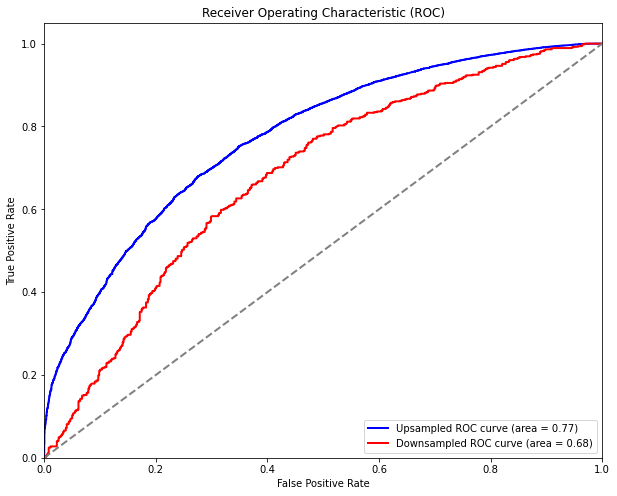

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import xgboost as xgb

# Load the data
data = pd.read_csv('merged.csv')

# Drop the specified columns
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns to avoid characters that XGBoost doesn't like
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

# Separate signal and background
signal = data[data['Label'] == 1]
background = data[data['Label'] == 0]

# Upsampling background
background_upsampled = resample(background, replace=True, n_samples=len(signal), random_state=42)
upsampled = pd.concat([signal, background_upsampled])

# Downsampling signal
signal_downsampled = resample(signal, replace=False, n_samples=len(background), random_state=42)
downsampled = pd.concat([signal_downsampled, background])

# Separate features and labels
def get_features_labels(df):
    X = df.drop('Label', axis=1)
    y = df['Label']
    return X, y

X_up, y_up = get_features_labels(upsampled)
X_down, y_down = get_features_labels(downsampled)

# Splitting the datasets
X_train_up, X_test_up, y_train_up, y_test_up = train_test_split(X_up, y_up, test_size=0.2, random_state=200)
X_train_down, X_test_down, y_train_down, y_test_down = train_test_split(X_down, y_down, test_size=0.2, random_state=42)

# XGBoost model
model = xgb.XGBClassifier(objective='binary:logistic', learning_rate=0.1, max_depth=5, n_estimators=100)

def train_evaluate(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    return fpr, tpr, roc_auc

# Upsampled dataset
fpr_up, tpr_up, roc_auc_up = train_evaluate(model, X_train_up, y_train_up, X_test_up, y_test_up)

# Downsampled dataset
fpr_down, tpr_down, roc_auc_down = train_evaluate(model, X_train_down, y_train_down, X_test_down, y_test_down)

# Plotting ROC Curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_up, tpr_up, color='blue', lw=2, label=f'Upsampled ROC curve (area = {roc_auc_up:.2f})')
plt.plot(fpr_down, tpr_down, color='red', lw=2, label=f'Downsampled ROC curve (area = {roc_auc_down:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()



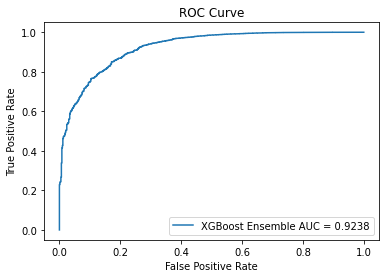

In [54]:
## Boosting with XGBoost
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import xgboost as xgb

# Load data
data = pd.read_csv('merged.csv')
# Drop the specified columns
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns to avoid characters that XGBoost doesn't like
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

X = data.drop('Label', axis=1)
y = data['Label']

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Bagging-like ensemble with XGBoost
n_estimators = 10
predictions = np.zeros((len(X_test), n_estimators))

for i in range(n_estimators):
    # Create a bootstrapped dataset
    bootstrapped_data = data.sample(frac=1, replace=True, random_state=i)
    X_boot = bootstrapped_data.drop('Label', axis=1)
    y_boot = bootstrapped_data['Label']

    # Train XGBoost on the bootstrapped dataset
    model = xgb.XGBClassifier()
    model.fit(X_boot, y_boot)
    predictions[:, i] = model.predict_proba(X_test)[:, 1]

# Averaging predictions
avg_prediction = predictions.mean(axis=1)

# Calculate ROC AUC
roc_auc = roc_auc_score(y_test, avg_prediction)

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, avg_prediction)
plt.plot(fpr, tpr, label=f"XGBoost Ensemble AUC = {roc_auc:.4f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()


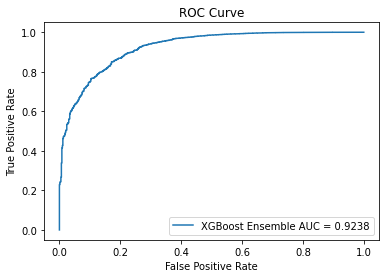

In [55]:
## Boosting with XGBoost
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import xgboost as xgb

# Load data
data = pd.read_csv('merged.csv')
# Drop the specified columns
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns to avoid characters that XGBoost doesn't like
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

X = data.drop('Label', axis=1)
y = data['Label']

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Bagging-like ensemble with XGBoost
n_estimators = 10
predictions = np.zeros((len(X_test), n_estimators))

for i in range(n_estimators):
    # Create a bootstrapped dataset
    bootstrapped_data = data.sample(frac=1, replace=True, random_state=i)
    X_boot = bootstrapped_data.drop('Label', axis=1)
    y_boot = bootstrapped_data['Label']

    # Train XGBoost on the bootstrapped dataset
    model = xgb.XGBClassifier()
    model.fit(X_boot, y_boot)
    predictions[:, i] = model.predict_proba(X_test)[:, 1]

# Averaging predictions
avg_prediction = predictions.mean(axis=1)

# Calculate ROC AUC
roc_auc = roc_auc_score(y_test, avg_prediction)

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, avg_prediction)
plt.plot(fpr, tpr, label=f"XGBoost Ensemble AUC = {roc_auc:.4f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()


/Users/arpanghosal/Downloads/ENTER/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/Users/arpanghosal/Downloads/ENTER/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


Accuracy: 0.9910
Precision: 0.9911
Recall: 0.9999
F1 Score: 0.9955


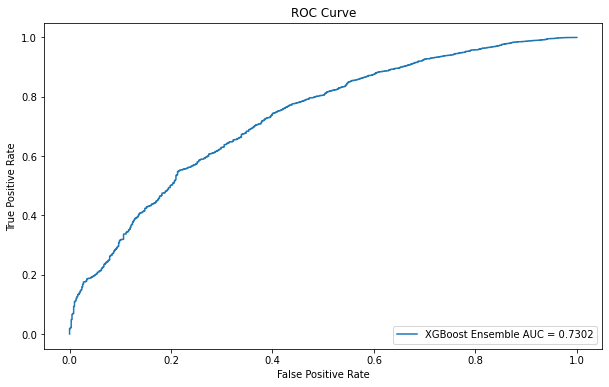

<Figure size 720x432 with 0 Axes>

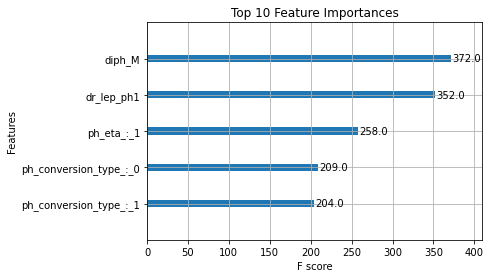

In [56]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import xgboost as xgb

# Load data
data = pd.read_csv('merged.csv')
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

X = data.drop('Label', axis=1)
y = data['Label']

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Hyperparameter tuning
param_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'n_estimators': [100, 200]
}
xgb_model = xgb.XGBClassifier()
grid_search = GridSearchCV(xgb_model, param_grid, cv=3, scoring='roc_auc')
grid_search.fit(X_train, y_train)
best_params = grid_search.best_params_

# Bagging-like ensemble with XGBoost with early stopping
n_estimators = 10
predictions = np.zeros((len(X_test), n_estimators))

for i in range(n_estimators):
    bootstrapped_data = data.sample(frac=1, replace=True, random_state=i)
    X_boot = bootstrapped_data.drop('Label', axis=1)
    y_boot = bootstrapped_data['Label']

    model = xgb.XGBClassifier(**best_params)
    eval_set = [(X_test, y_test)]
    
    model.fit(X_boot, y_boot, early_stopping_rounds=10, eval_metric="logloss", eval_set=eval_set, verbose=False)
    
    predictions[:, i] = model.predict_proba(X_test)[:, 1]

# Averaging predictions
avg_prediction = predictions.mean(axis=1)

# Calculate metrics
roc_auc = roc_auc_score(y_test, avg_prediction)
accuracy = accuracy_score(y_test, np.round(avg_prediction))
precision = precision_score(y_test, np.round(avg_prediction))
recall = recall_score(y_test, np.round(avg_prediction))
f1 = f1_score(y_test, np.round(avg_prediction))

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, avg_prediction)
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"XGBoost Ensemble AUC = {roc_auc:.4f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

# Feature importance plot
plt.figure(figsize=(10, 6))
xgb.plot_importance(model, max_num_features=10)
plt.title("Top 10 Feature Importances")
plt.show()


/Users/arpanghosal/Downloads/ENTER/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


ROC AUC: 0.9238


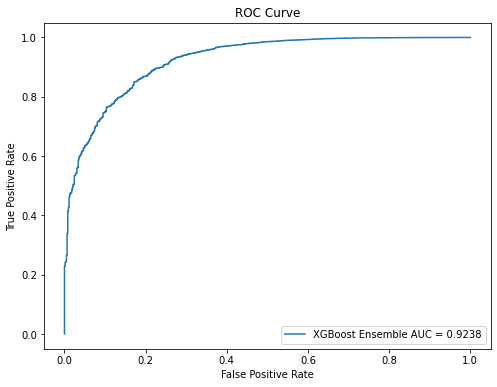

Accuracy: 0.9911
Precision: 0.9911
Recall: 1.0000
F1 Score: 0.9956


In [57]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import xgboost as xgb

# Load data
data = pd.read_csv('merged.csv')
# Drop the specified columns
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns to avoid characters that XGBoost doesn't like
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

X = data.drop('Label', axis=1)
y = data['Label']

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Bagging-like ensemble with XGBoost
n_estimators = 10
predictions = np.zeros((len(X_test), n_estimators))

best_params = {
    # Add the optimized parameters you've found here
    # 'max_depth': 3, 'learning_rate': 0.1, ... (for example)
}
best_params['eval_metric'] = 'logloss'

for i in range(n_estimators):
    # Create a bootstrapped dataset
    bootstrapped_data = data.sample(frac=1, replace=True, random_state=i)
    X_boot = bootstrapped_data.drop('Label', axis=1)
    y_boot = bootstrapped_data['Label']

    # Train XGBoost on the bootstrapped dataset
    model = xgb.XGBClassifier(**best_params)
    model.fit(X_boot, y_boot, early_stopping_rounds=10, eval_set=[(X_test, y_test)], verbose=False)
    predictions[:, i] = model.predict_proba(X_test)[:, 1]

# Averaging predictions
avg_prediction = predictions.mean(axis=1)

# Calculate and display ROC AUC
roc_auc = roc_auc_score(y_test, avg_prediction)
print(f"ROC AUC: {roc_auc:.4f}")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, avg_prediction)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"XGBoost Ensemble AUC = {roc_auc:.4f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

# Additional Metrics
y_pred = (avg_prediction > 0.5).astype(int)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")



ROC AUC: 0.9238


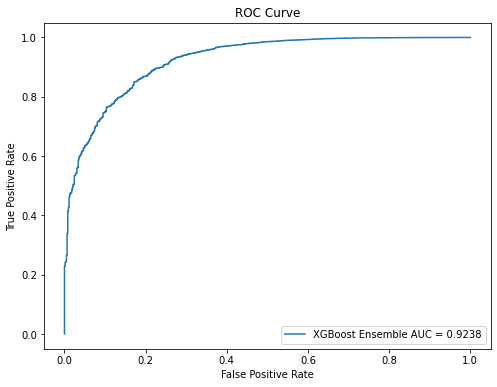

Accuracy: 0.9911
Precision: 0.9911
Recall: 1.0000
F1 Score: 0.9956


In [58]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import xgboost as xgb

# Load data
data = pd.read_csv('merged.csv')
# Drop the specified columns
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns to avoid characters that XGBoost doesn't like
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

X = data.drop('Label', axis=1)
y = data['Label']

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Bagging-like ensemble with XGBoost
n_estimators = 10
predictions = np.zeros((len(X_test), n_estimators))

best_params = {
    # Add the optimized parameters you've found here
    # 'max_depth': 3, 'learning_rate': 0.1, ... (for example)
    'eval_metric': 'logloss', 
    'learning_rate': 0.1
    'early_stopping_rounds': 100
}

for i in range(n_estimators):
    # Create a bootstrapped dataset
    bootstrapped_data = data.sample(frac=1, replace=True, random_state=i)
    X_boot = bootstrapped_data.drop('Label', axis=1)
    y_boot = bootstrapped_data['Label']

    # Train XGBoost on the bootstrapped dataset
    model = xgb.XGBClassifier(**best_params)
    model.fit(X_boot, y_boot, eval_set=[(X_test, y_test)], verbose=False)
    predictions[:, i] = model.predict_proba(X_test)[:, 1]

# Averaging predictions
avg_prediction = predictions.mean(axis=1)

# Calculate and display ROC AUC
roc_auc = roc_auc_score(y_test, avg_prediction)
print(f"ROC AUC: {roc_auc:.4f}")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, avg_prediction)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"XGBoost Ensemble AUC = {roc_auc:.4f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

# Additional Metrics
y_pred = (avg_prediction > 0.5).astype(int)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best hyperparameters:
 {'subsample': 0.6, 'n_estimators': 300, 'learning_rate': 0.01, 'colsample_bytree': 0.7}
ROC AUC: 0.7460


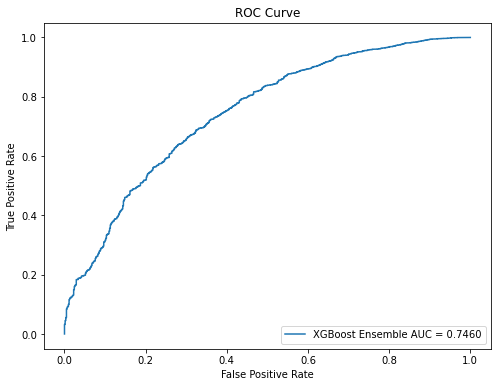

Accuracy: 0.9910
Precision: 0.9910
Recall: 1.0000
F1 Score: 0.9955


In [63]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import xgboost as xgb

# Load data
data = pd.read_csv('merged.csv')
columns_to_drop = ['Sample_Name', 'Sample_Type', 'eventNumber', 'Weight']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

# Rename columns
data.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in data.columns]

X = data.drop('Label', axis=1)
y = data['Label']

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Hyperparameter optimization
param_dist = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    #'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
    'n_estimators': [50, 100, 150, 200, 300],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0]
}

model = xgb.XGBClassifier(eval_metric='logloss') #, early_stopping_rounds=10)
rscv = RandomizedSearchCV(model, param_dist, scoring='roc_auc', n_iter=10, verbose=1, n_jobs=1, cv=3, random_state=42)
rscv.fit(X_train, y_train)

best_params = rscv.best_params_
print("Best hyperparameters:\n", best_params)

# Bagging-like ensemble with XGBoost
n_estimators = 10
predictions = np.zeros((len(X_test), n_estimators))

for i in range(n_estimators):
    bootstrapped_data = data.sample(frac=1, replace=True, random_state=i)
    X_boot = bootstrapped_data.drop('Label', axis=1)
    y_boot = bootstrapped_data['Label']
    
    model = xgb.XGBClassifier(**best_params, eval_metric='logloss', early_stopping_rounds=10)
    model.fit(X_boot, y_boot, eval_set=[(X_test, y_test)], verbose=False)
    predictions[:, i] = model.predict_proba(X_test)[:, 1]

# Averaging predictions
avg_prediction = predictions.mean(axis=1)

# Calculate and display ROC AUC
roc_auc = roc_auc_score(y_test, avg_prediction)
print(f"ROC AUC: {roc_auc:.4f}")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, avg_prediction)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"XGBoost Ensemble AUC = {roc_auc:.4f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

# Additional Metrics
y_pred = (avg_prediction > 0.5).astype(int)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")


In [33]:
## SMOTE 

import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, auc
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import numpy as np

# 1. Data Loading and Initial Processing
data = pd.read_csv('merged.csv')
print(data.head())

columns_to_drop = ['Sample_Name', 'Sample_Type']
data.drop(columns=columns_to_drop, axis=1, inplace=True)

X = data.drop('Label', axis=1)
y = data['Label']

# Rename columns to avoid characters XGBoost doesn't like
X.columns = [col.replace('[', '_').replace(']', '').replace(',', '_') for col in X.columns]

# 2. Preprocessing and Class Balancing using SMOTE
X = X.fillna(X.median())
X = pd.get_dummies(X)

# Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Split the resampled data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# 3. Model Training and Evaluation
model = xgb.XGBClassifier(objective ='binary:logistic', learning_rate = 0.1, max_depth = 5, n_estimators = 100)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

# ROC Curve
y_pred_prob = model.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()


ImportError: cannot import name '_OneToOneFeatureMixin' from 'sklearn.base' (/Users/arpanghosal/Downloads/ENTER/lib/python3.9/site-packages/sklearn/base.py)

In [38]:
from imblearn.over_sampling import SMOTE

ImportError: cannot import name '_OneToOneFeatureMixin' from 'sklearn.base' (/Users/arpanghosal/Downloads/ENTER/lib/python3.9/site-packages/sklearn/base.py)